════════════════════════════════════════════════════

PROJECT TITLE : AI-Based Anomaly Detection and Intelligent Monitoring of Chiller Operating Data

DATASET : Raw Chiller dataset provided by the instructor.

Course : Artificial Intelligence - BCSE306L

Name                : V C Pavitran

Register Number     : 24BCE2019

Track               : Multivariate and time-series detection

Assigned Method     : XGBoost prediction-residual detector

Preprocessing       : Lag features; chronological split

Evaluation Method   : RMSE; residual threshold sensitivity

Research Question   : Can gradient-boosted prediction errors detect unusual
operating conditions?

Label Notes         : Unsupervised residual detection; target must be available

════════════════════════════════════════════════════

Open in collab and upload excel sheet and run all cells from top to bottom

In [1]:
!pip install xlrd

I loaded the file "Analyse Chillers_AI Course.xls". The first 3 rows were not data so skipped it, the data has 522 rows and 60 columns.

In [2]:
import pandas as pd

df = pd.read_excel("Analyse Chillers_AI Course.xls", header=2)
print(df.shape)
df.head()

(522, 60)


,Sl.No,CHILLER TAG,Date,Time,Evaporator Water In Temperature Deg C,Evaporator Water Out Temperature Deg C,Condenser Water In Temperature Deg C,Condenser Water Out Temperature Deg C,Running Load % Comp 1,Running Load % Comp 2,...,Condenser Pump Discharge Pressure Bar,Condenser Pump Current R Amps,Condenser Pump Current Y Amps,Condenser Pump Current B Amps,Cooling Tower Motor Current Fan 1 R Amps,Cooling Tower Motor Current Fan 1 Y Amps,Cooling Tower Motor Current Fan 1 B Amps,Cooling Tower Motor Current Fan 2 R Amps,Cooling Tower Motor Current Fan 2 Y Amps,Cooling Tower Motor Current Fan 2 B Amps
0,1,Chiller - 5,2026-03-20,08:00:00,8.6,7.1,28.2,30.4,51.9,76.3,...,0.0,67.2,60.0,62.3,16.4,16.0,17.4,15.2,13.8,17.5
1,2,Chiller - 5,2026-03-20,07:00:00,8.7,6.9,28.2,30.7,51.9,85.3,...,0.0,64.2,62.8,62.5,17.0,15.9,17.6,14.9,13.8,18.4
2,3,Chiller - 5,2026-03-20,06:00:00,9.0,7.0,28.5,31.0,52.8,86.0,...,0.0,67.7,62.5,62.6,17.6,14.5,17.9,16.8,14.5,16.8
3,4,Chiller - 1,2026-03-20,08:00:00,8.4,6.9,28.2,30.4,84.4,48.1,...,0.0,67.2,61.6,62.6,17.0,15.3,18.8,18.0,16.1,18.9
4,5,Chiller - 1,2026-03-20,07:00:00,8.5,6.7,28.5,30.7,92.5,47.8,...,0.0,65.3,62.8,62.5,19.8,20.9,22.0,18.6,17.2,18.9


The file was in reverse order so i sorted it . Also joined date and time before sorting.


In [3]:
df["Timestamp"] = pd.to_datetime(df["Date"].astype(str).str[:10] + " " + df["Time"].astype(str))
df = df.sort_values("Timestamp").reset_index(drop=True)
print(df["Timestamp"].isna().sum())
df[["CHILLER TAG", "Timestamp"]].head(10)

0


,CHILLER TAG,Timestamp
0,Chiller - 1,2026-03-11 00:00:00
1,Chiller - 1,2026-03-11 01:00:00
2,Chiller - 1,2026-03-11 02:00:00
3,Chiller - 1,2026-03-11 03:00:00
4,Chiller - 5,2026-03-11 03:00:00
5,Chiller - 1,2026-03-11 04:00:00
6,Chiller - 5,2026-03-11 04:00:00
7,Chiller - 1,2026-03-11 05:00:00
8,Chiller - 5,2026-03-11 05:00:00
9,Chiller - 1,2026-03-11 06:00:00


Picking chiller 4 alone because of its immense data comapred to other chillers so it would help in the ML process.

In [4]:
c4 = df[df["CHILLER TAG"] == "Chiller - 4"].copy().reset_index(drop=True)
gaps = c4["Timestamp"].diff()
print(len(c4))
print(c4.loc[gaps > pd.Timedelta("1h"), "Timestamp"])
print(gaps[gaps > pd.Timedelta("1h")])

131
4     2026-03-11 17:00:00
30    2026-03-13 10:00:00
61    2026-03-16 11:00:00
75    2026-03-17 03:00:00
116   2026-03-19 00:00:00
117   2026-03-19 02:00:00
118   2026-03-19 05:00:00
Name: Timestamp, dtype: datetime64[ns]
4     0 days 05:00:00
30    0 days 16:00:00
61    1 days 19:00:00
75    0 days 03:00:00
116   0 days 05:00:00
117   0 days 02:00:00
118   0 days 03:00:00
Name: Timestamp, dtype: timedelta64[ns]


QA for dataset -  no missing values and the columns Motor Current Comp 1 and 2, Discharge Temperature Comp 1 had anomalies , but kept them because they can indicate some issues in the chiller unit.

In [5]:
print(c4.isna().sum().sum())
print(c4.dtypes.value_counts())
c4.describe().T[["min", "mean", "max", "std"]]

0
float64           54
int64              3
object             2
datetime64[ns]     2
Name: count, dtype: int64


,min,mean,max,std
Sl.No,36.0,249.969466,508.0,149.589898
Date,2026-03-11 00:00:00,2026-03-15 05:40:45.801526784,2026-03-19 00:00:00,NaN
Evaporator Water In Temperature Deg C,8.5,9.787023,11.5,0.75104
Evaporator Water Out Temperature Deg C,6.9,7.779389,9.2,0.636302
Condenser Water In Temperature Deg C,27.3,29.761832,34.8,0.874023
Condenser Water Out Temperature Deg C,29.6,32.326718,37.4,1.012979
Running Load % Comp 1,51.0,96.732061,101.0,8.317454
Running Load % Comp 2,47.0,90.600763,100.0,14.654222
Motor Current Amps Comp 1,115.6,227.242748,1350.0,100.352125
Motor Current Amps Comp 2,100.0,209.79542,2106.0,169.93608


Checking a very high motor current and noting down the suspicious record. The row at March 12 2AM shows a motor current of 1350A at only 60% load which is inconsistent and unusual while the discharge temperature is at 6.3 degree C.

In [6]:
c4[c4["Motor Current Amps Comp 1"] > 600][["Timestamp", "Motor Current Amps Comp 1", "Running Load % Comp 1", "Discharge Temperature Deg C Comp 1"]]

,Timestamp,Motor Current Amps Comp 1,Running Load % Comp 1,Discharge Temperature Deg C Comp 1
13,2026-03-12 02:00:00,1350.0,60.0,6.3


The rows that appear after a long gap are removed because the ML model trains on data that appears in 1 hour intervals, so say for example if a row appears at 8:00 time and another appears at 14:00 time and the row afterr it is 15:00, we remove 14:00 time because there is a 6 hour gap in between and 15:00 is kept because it appears after 1 hour interval of 14:00 row. So we have a time consistent dataset.

In [7]:
c4["gap"] = c4["Timestamp"].diff()
ok = c4["gap"] == pd.Timedelta("1h")

for col in ["Evaporator Water Out Temperature Deg C",
            "Evaporator Water In Temperature Deg C",
            "Running Load % Comp 1"]:
    c4[col + " lag1"] = c4[col].shift(1).where(ok)

c4 = c4[ok].reset_index(drop=True)
print(c4.shape)

(123, 65)


ML Model:

Chooses which value to predict and picks the tempeerature of the water leaving the chiller , uses every column as information except, Sl.no., date, time , chiller name, and run hour counters. Training dataset is the first 70% of the chillers complete dataset and the rest 30% is the evaluation datset on which the ML model is tested. Measures RMSE in degree Celsius.

In [8]:
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

target = "Evaporator Water Out Temperature Deg C"
drop_cols = ["Sl.No", "Date", "Time", "CHILLER TAG", "Timestamp", "gap",
             "Compressure Run Hours Comp 1", "Compressure Run Hours Comp 2", target]

X = c4.drop(columns=drop_cols)
y = c4[target]

split = int(len(c4) * 0.7)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

model = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)

rmse_train = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
rmse_test = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
print(X.shape, len(X_train), len(X_test))
print("RMSE train:", rmse_train, " RMSE test:", rmse_test)

(123, 56) 86 37
RMSE train: 0.009574286644672641  RMSE test: 0.1427985266949586


In [9]:
res_train = y_train - model.predict(X_train)
res_test = y_test - model.predict(X_test)
print("train residual std:", res_train.std(), " test residual std:", res_test.std())

for k in [1, 1.5, 2, 2.5, 3]:
    thr = k * res_test.std()
    print("k =", k, " threshold =", round(thr, 3), " flagged:", (res_test.abs() > thr).sum(), "of", len(res_test))

thr_train = 3 * res_train.std()
print("threshold from training residuals:", thr_train, " flagged on test:", (res_test.abs() > thr_train).sum())

train residual std: 0.009630151228362041  test residual std: 0.1437272598466934
k = 1  threshold = 0.144  flagged: 8 of 37
k = 1.5  threshold = 0.216  flagged: 2 of 37
k = 2  threshold = 0.287  flagged: 1 of 37
k = 2.5  threshold = 0.359  flagged: 1 of 37
k = 3  threshold = 0.431  flagged: 1 of 37
threshold from training residuals: 0.028890453685086123  flagged on test: 26


In [10]:
thr = 2 * res_test.std()
flagged = c4.loc[X_test.index[res_test.abs() > thr], ["Timestamp", target]]
flagged

,Timestamp,Evaporator Water Out Temperature Deg C
104,2026-03-18 13:00:00,9.0


In [11]:
res_test.loc[104]

np.float64(0.6302070617675781)

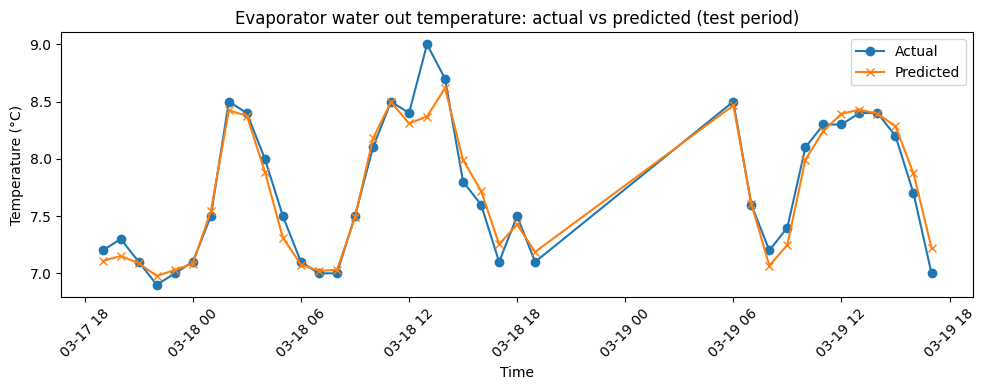

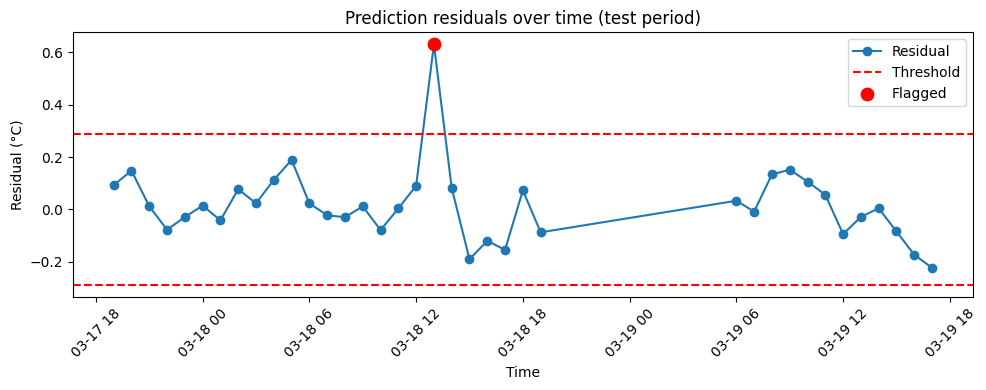

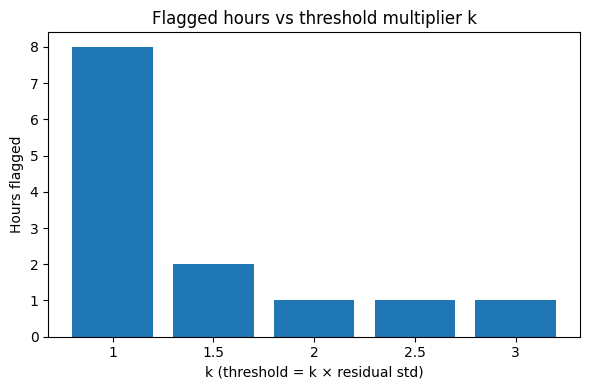

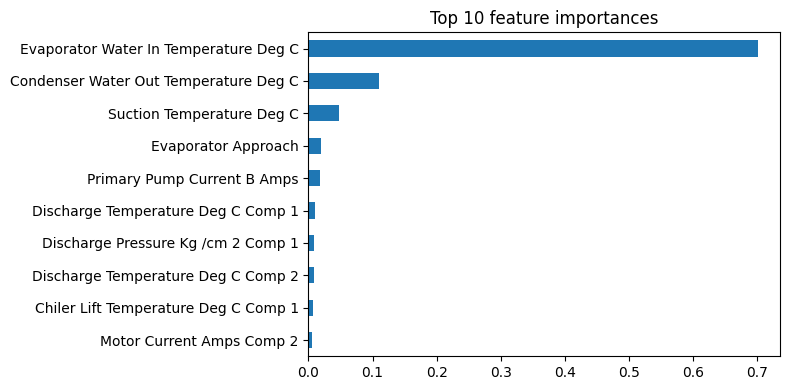

In [12]:
import matplotlib.pyplot as plt

t_test = c4.loc[X_test.index, "Timestamp"]
pred_test = model.predict(X_test)
thr = 2 * res_test.std()
flag = res_test.abs() > thr

# Plot 1: actual vs predicted
plt.figure(figsize=(10, 4))
plt.plot(t_test, y_test, marker="o", label="Actual")
plt.plot(t_test, pred_test, marker="x", label="Predicted")
plt.title("Evaporator water out temperature: actual vs predicted (test period)")
plt.xlabel("Time"); plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

# Plot 2: residuals with threshold and flagged points
plt.figure(figsize=(10, 4))
plt.plot(t_test, res_test, marker="o", label="Residual")
plt.axhline(thr, color="red", linestyle="--", label="Threshold")
plt.axhline(-thr, color="red", linestyle="--")
plt.scatter(t_test[flag], res_test[flag], color="red", s=80, zorder=3, label="Flagged")
plt.title("Prediction residuals over time (test period)")
plt.xlabel("Time"); plt.ylabel("Residual (°C)")
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

# Plot 3: threshold sensitivity
ks = [1, 1.5, 2, 2.5, 3]
counts = [(res_test.abs() > k * res_test.std()).sum() for k in ks]
plt.figure(figsize=(6, 4))
plt.bar([str(k) for k in ks], counts)
plt.title("Flagged hours vs threshold multiplier k")
plt.xlabel("k (threshold = k × residual std)"); plt.ylabel("Hours flagged")
plt.tight_layout(); plt.show()

# Plot 4 (extra): most important inputs
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(10)
plt.figure(figsize=(8, 4))
imp.plot(kind="barh")
plt.title("Top 10 feature importances"); plt.tight_layout(); plt.show()